In [1]:
import sys

import numpy as np
import pandas as pd
import pathlib
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc

from pathlib import Path
# sys.path.append('../src')
# from utils import *

import warnings
warnings.filterwarnings('ignore')

from gctsvg.preprocessing import common, singlecell, kidneycancer

In [2]:
data_dir = Path('data_repo/Human Kidney Cancer')
output_dir = Path('scRNA ref checkpoints/Human Kidney Cancer')
patient_id='PD47171'
cell_type_column='broad_type'
num_samples_per_type=3000
n_top_hvgs=3000
n_top_markers=100

In [3]:
# read scRNA data
adata_sc = sc.read(data_dir / 'RCC_upload_final_raw_counts.h5ad')
adata_sc.var_names_make_unique()

In [4]:
adata_sc = kidneycancer.extract_sc_patient_data(adata_sc, patient_id)

In [5]:
# extract cell type information
cell_types, n_classes = singlecell.get_cell_types(adata_sc, cell_type_column)

In [6]:
adata_sc.obs.groupby(cell_type_column).count()["orig.ident"].values

array([  519,    46,    21,    48,    32,     4,  5990,  1576,   144,
        2350, 25307,    73])

In [7]:
is_mt_gene=lambda adata: adata.var['name'].str.startswith('MT-')

In [8]:
adata_sc = common.filter(adata_sc, is_mt_gene=is_mt_gene, min_locs=20, min_genes=20)

In [9]:
# Format data to use ENSEMBL gene id as index
# necessary to align indexes of st and sc datasets
adata_sc = common.use_ensembl_gene_ids(adata_sc, 'name')

In [10]:
# sample by cell type
adata_sc = singlecell.sample_cells_per_type(adata_sc, cell_type_column, num_samples_per_type)

In [11]:
adata_sc.obs.groupby(cell_type_column).count()

,orig.ident,nCount_RNA,nFeature_RNA,patient,percent.mt,summaryDescription,annotation,region
broad_type,,,,,,,,
B-cell,519,519,519,519,519,519,519,519
EC,46,46,46,46,46,46,46,46
Epi_non-PT,21,21,21,21,21,21,21,21
Epi_PT,48,48,48,48,48,48,48,48
Fibro,32,32,32,32,32,32,32,32
Mast,4,4,4,4,4,4,4,4
Myeloid,3000,3000,3000,3000,3000,3000,3000,3000
NK,1576,1576,1576,1576,1576,1576,1576,1576
Plasma,144,144,144,144,144,144,144,144


In [12]:
adata_sc

AnnData object with n_obs × n_vars = 10813 × 15688
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'patient', 'percent.mt', 'summaryDescription', 'annotation', 'region', 'broad_type'
    var: 'SYMBOL'
    uns: 'annotation_colors', 'broad_type_colors', 'region_colors', 'summaryDescription_colors'
    obsm: 'X_pca', 'X_umap'

In [13]:
# preprocess sc data
sc_target_sum = 1e3
sc_max = 10

common.preprocess(adata_sc, sc_target_sum, sc_max)
# adata_sc

In [14]:
# get_marker_genes
markers = singlecell.get_marker_genes(adata_sc, cell_type_column, n_top_hvgs, n_top_markers)

In [15]:
pd.DataFrame(adata_sc.uns['rank_genes_groups']['names']).iloc[0:100,:].melt().value.values

array(['ENSG00000105369', 'ENSG00000104894', 'ENSG00000156738', ...,
       'ENSG00000282694', 'ENSG00000204487', 'ENSG00000231314'],
      dtype=object)

In [16]:
adata_sc.var.loc[adata_sc.var.index.isin(markers),'Marker'] = True
adata_sc.var['Marker'] = adata_sc.var['Marker'].fillna(False)
adata_sc.var['highly_variable'] = adata_sc.var['Marker']
adata_sc.X.max()

6.540396

In [17]:
sc.pp.pca(adata_sc,svd_solver='arpack', n_comps=30, use_highly_variable=True)
sc.pp.neighbors(adata_sc, metric='cosine', n_neighbors=30, n_pcs = 30)
sc.tl.umap(adata_sc, min_dist = 0.5, spread = 1, maxiter=60)

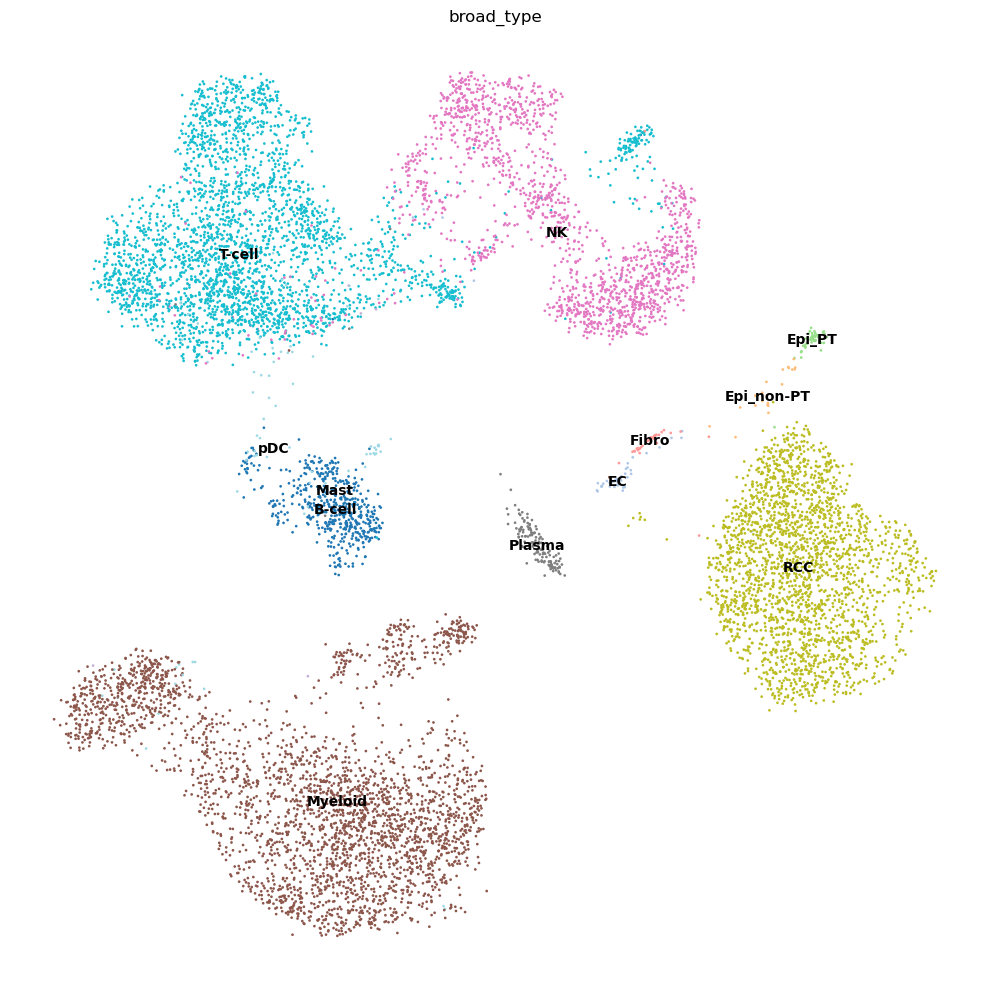

In [18]:
fig, axs = plt.subplots(1, 1, figsize=(10, 10))
sc.pl.umap(
    adata_sc, color=cell_type_column, size=15, frameon=False, show=False, ax=axs,legend_loc='on data'
)
plt.tight_layout()

In [21]:
if not Path.exists(output_dir):
    Path.mkdir(output_dir, parents=True)
adata_sc.write(output_dir / 'Human Kidney Cancer.h5ad')

```
python ./SpatialScope/src/Train_scRef.py \
--ckpt_path ./"scRNA ref checkpoints"/"Human Kidney Cancer" \
--scRef ./"scRNA ref checkpoints"/"Human Kidney Cancer"/"Human Kidney Cancer".h5ad \
--cell_class_column broad_type \
--gpus 0,1,2,3 \
--sigma_begin 50 --sigma_end 0.002 --step_lr 3e-7
```

In [25]:
adata_sc.n_vars

15688

In [27]:
adata_sc.var[adata_sc.var['highly_variable']]

,SYMBOL,highly_variable,highly_variable_rank,means,variances,variances_norm,Marker
ENSEMBL,,,,,,,
ENSG00000187583,PLEKHN1,True,2931.0,0.001382,0.000408,1.053019,True
ENSG00000188290,HES4,True,1431.0,0.015771,0.005190,1.286251,True
ENSG00000187608,ISG15,True,1982.0,0.082328,0.027052,1.159579,True
ENSG00000188157,AGRN,True,2039.0,0.014435,0.004265,1.149952,True
ENSG00000186891,TNFRSF18,True,1063.0,0.007156,0.002744,1.425316,True
...,...,...,...,...,...,...,...
ENSG00000103355,PRSS33,True,1628.0,0.002955,0.001033,1.229176,True
ENSG00000174448,STARD6,True,1298.0,0.000156,0.000050,1.336639,True
ENSG00000269416,LINC01224,True,2406.0,0.000208,0.000056,1.102712,True


In [28]:
adata_sc.n_obs

10813